# Neural network: predict position (multi-position aware)
**Task:** classify outfield players as DF / MF / FW from playing-style stats, with position hidden.

**Fix:** a player listed as `MF,FW` is **correct if the prediction is either MF or FW**. Training also respects this: each dual-position player contributes one row per listed position (duplicated rows, since `MLPClassifier` has no sample weights).

**Leakage guard:** train/test split is per player *before* rows are duplicated. No `Pos` / `Pos_stats_*` column is a feature. Early stopping is off, because its internal validation split would otherwise put duplicate rows of one player on both sides.

**Model:** scikit-learn `MLPClassifier`, scaler inside the pipeline.

In [1]:
%pip install -q scikit-learn pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
df = pd.read_csv('players_data-2026_2027.csv'); print(df.shape)

(2295, 102)


In [2]:
d = df[df['Pos'].notna() & ~df['Pos'].str.contains('GK')].copy()
d = d[d['90s'] >= 3].drop_duplicates(subset=['Player','Squad']).reset_index(drop=True)
names = ['DF','MF','FW']
d['pos_set'] = d['Pos'].str.split(',').apply(lambda l: [p.strip() for p in l if p.strip() in names])
d = d[d['pos_set'].str.len() > 0].reset_index(drop=True)
d['multi'] = d['pos_set'].str.len() > 1

counts = ['Gls','Ast','Sh','SoT','Crs','Int','TklW','Fld','Fls','Off','CrdY','CrdR','PKatt']
for k in counts: d[k+'_90'] = d[k] / d['90s']
feats = [k+'_90' for k in counts] + ['Age','Min%','Mn/Start','Starts','90s']
feats = [f for f in feats if f in d.columns]
d[feats] = d[feats].fillna(0)
assert not any('Pos' in f for f in feats)
print(len(d), 'players |', d['multi'].sum(), 'list more than one position')

1268 players | 227 list more than one position


Test accuracy (any listed position counts): 0.783
Old metric (first-listed position only):     0.701
Single-position players: 0.744 | Multi-position players: 0.977


/opt/anaconda3/envs/tf_env/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


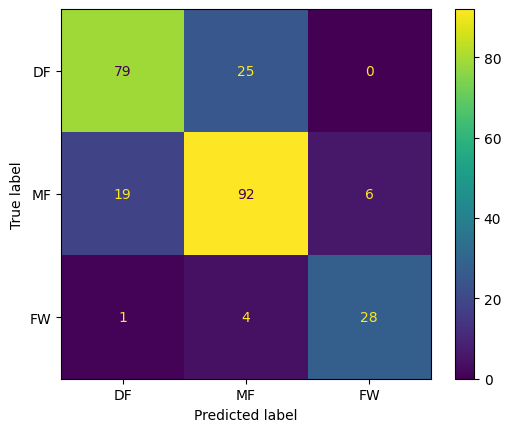

In [3]:
idx = {n:i for i,n in enumerate(names)}
def expand(frame):
    rows = frame.explode('pos_set')
    return rows[feats], rows['pos_set'].map(idx)

def set_accuracy(model, frame):
    pred = model.predict(frame[feats])
    ok = np.array([names[p] in s for p, s in zip(pred, frame['pos_set'])])
    return ok.mean(), pred, ok

def make():
    return make_pipeline(StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(32,16), alpha=1e-2, max_iter=500, random_state=42))

tr, te = train_test_split(d, test_size=0.2, random_state=42)
Xtr, ytr = expand(tr)
nn = make().fit(Xtr, ytr)
acc, pred, ok = set_accuracy(nn, te)
first = te['pos_set'].str[0].map(idx).values
print('Test accuracy (any listed position counts): %.3f' % acc)
print('Old metric (first-listed position only):     %.3f' % (pred == first).mean())
print('Single-position players: %.3f | Multi-position players: %.3f' % (ok[~te['multi'].values].mean(), ok[te['multi'].values].mean()))
true_for_cm = [names[p] if names[p] in s else s[0] for p, s in zip(pred, te['pos_set'])]
ConfusionMatrixDisplay(confusion_matrix(true_for_cm, [names[p] for p in pred], labels=names), display_labels=names).plot(); plt.show()

/opt/anaconda3/envs/tf_env/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/tf_env/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/tf_env/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/tf_env/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


5-fold accuracy (any listed position counts): 0.767 +/- 0.013


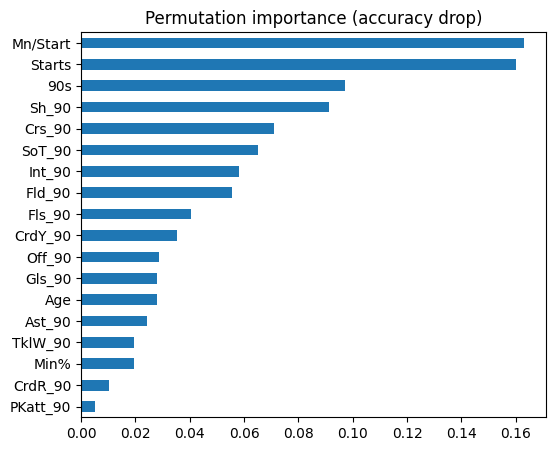

In [4]:
accs = []
for a, b in KFold(5, shuffle=True, random_state=42).split(d):
    X_, y_ = expand(d.iloc[a]); accs.append(set_accuracy(make().fit(X_, y_), d.iloc[b])[0])
print('5-fold accuracy (any listed position counts): %.3f +/- %.3f' % (np.mean(accs), np.std(accs)))

from sklearn.inspection import permutation_importance
tei = te.copy(); tei['y'] = [names.index(names[p]) if names[p] in s else idx[s[0]] for p, s in zip(pred, te['pos_set'])]
r = permutation_importance(nn, te[feats], tei['y'], n_repeats=20, random_state=42)
pd.Series(r.importances_mean, feats).sort_values().plot.barh(figsize=(6,5), title='Permutation importance (accuracy drop)'); plt.show()

In [5]:
proba = pd.DataFrame(nn.predict_proba(te[feats]), columns=names, index=te.index).round(2)
res = pd.concat([te[['Player','Squad','Pos']], proba], axis=1)
res['pred'] = [names[p] for p in pred]; res['correct'] = ok
print('Wrong even with multi-position credit, most confident first')
res[~res.correct].assign(conf=proba.max(axis=1)).sort_values('conf', ascending=False).head(15)

Wrong even with multi-position credit, most confident first


,Player,Squad,Pos,DF,MF,FW,pred,correct,conf
974,Federico Redondo,Elche,DF,0.00,1.00,0.00,MF,False,1.00
575,Christian Kabasele,Udinese,DF,0.00,1.00,0.00,MF,False,1.00
58,Jon Aramburu,Real Sociedad,DF,0.00,1.00,0.00,MF,False,1.00
543,Merwan Ifnaoui,Troyes,"FW,MF",1.00,0.00,0.00,DF,False,1.00
746,Ephron Mason-Clark,Coventry City,MF,0.00,0.01,0.99,FW,False,0.99
196,Lamine Camara,Monaco,MF,0.99,0.01,0.00,DF,False,0.99
532,Morten Hjulmand,Atlético Madrid,MF,0.99,0.01,0.00,DF,False,0.99
140,Antonio Blanco,Alavés,MF,0.98,0.02,0.00,DF,False,0.98
1107,Djibril Sow,Genoa,MF,0.98,0.02,0.00,DF,False,0.98
888,Fredrik Oppegard,Auxerre,MF,0.97,0.03,0.00,DF,False,0.97


**Notes:** dual-position players are easy to score because two of three answers are accepted, so compare the single-position figure too. Try tuning `hidden_layer_sizes` / `alpha`, or add passing and defending stats.

## Added experiment: do advanced WhoScored predictors improve position accuracy?

This section is self-contained and was appended after the existing analysis. It preserves the original experiment and outputs.

**Comparison:** the same verified players, target labels, training splits and estimator, with **12 baseline predictors** versus **23 predictors after adding the 11 advanced statistics**. Success means predicting any officially listed position, matching the scoring above. Single-position and first-listed results are also shown.

**Reporting-period alignment:** the earlier numeric CSV is a 2 November snapshot. Both numeric feature blocks here use current 2026/27 WhoScored totals with identical player/club/league, appearances and minutes. The earlier CSV supplies position labels and eligibility only; its old performance counters are not mixed into the new model. Matching uses exact name aliases, explicit club aliases, nationality and age checks. Players with changed exposure between source captures are excluded.

**Model:** `MLPClassifier((32, 16), alpha=0.01, max_iter=1500, random_state=42, early_stopping=False)`. The network retains the original (32, 16) hidden layers and alpha=0.01. Alternative labels are expanded only inside training folds, as above; early stopping remains off. Both arms use the same 1,500-iteration cap to allow more convergence time than the original 500.

The common baseline is the original linear notebook's core: shots, shots on target, goals, assists, crosses, interceptions, tackles won, the two source foul counts, offsides and yellow cards per 90, plus age. The logistic and neural comparisons use this same core rather than retaining old playing-time proxies that cannot be updated consistently. **The stored results earlier in the notebook are context, not the baseline for this paired experiment.**

In [1]:
# Run this appended section independently; no variables from earlier cells are required.
from pathlib import Path as adv_Path
import sys as adv_sys
import numpy as adv_np
import pandas as adv_pd
import matplotlib.pyplot as adv_plt
from IPython.display import display as adv_display, Markdown as adv_Markdown

adv_project = adv_Path.cwd()
if not (adv_project / 'advanced_position_comparison.py').is_file():
    adv_project = adv_project / 'AI_Football_Project'
if str(adv_project) not in adv_sys.path:
    adv_sys.path.insert(0, str(adv_project))
from advanced_position_comparison import (
    BASE_FEATURES as adv_base_features, ADVANCED_FEATURES as adv_extra_features,
    OUT as adv_output, run_experiment as adv_run_experiment,
    summary_table as adv_summary_table, conclusion as adv_conclusion,
)

adv_model_kind = 'neural'
# Fits are cached only when the source-file and implementation hashes agree.
# Set force=True to recompute all paired fits from the frozen source captures.
adv_data, adv_cohort, adv_result = adv_run_experiment(adv_model_kind, force=False)
print(f"Compared {len(adv_data):,} verified records from {adv_cohort['old_notebook_eligible']:,} originally eligible records.")
print('Baseline predictors:', adv_base_features)
print('Added predictors:', adv_extra_features)

Compared 1,089 verified records from 1,268 originally eligible records.
Baseline predictors: ['Sh_p90', 'SoT_p90', 'Gls_p90', 'Ast_p90', 'Crs_p90', 'Int_p90', 'TklW_p90', 'foulGiven_p90', 'foulCommitted_p90', 'Off_p90', 'CrdY_p90', 'Age']
Added predictors: ['key_passes_p90', 'passes_p90', 'accurate_passes_p90', 'pass_completion_pct', 'long_balls_p90', 'successful_dribbles_p90', 'aerial_duels_won_p90', 'clearances_p90', 'blocks_p90', 'dispossessions_p90', 'poor_controls_p90']


### Results on identical players and splits

All count predictors use exact source minutes: `90 * total / minutes`; pass completion remains a percentage. Five-fold validation is stratified by the first-listed class and grouped by player ID. The additional 20% holdout uses player groups and seed 42. Row expansion, median imputation and numerical scaling happen inside training folds. Neither feature selection nor hyperparameter tuning uses the holdout.

In [2]:
adv_summary = adv_summary_table(adv_result)
adv_formatted_summary = adv_summary.copy()
for adv_column in adv_formatted_summary.columns:
    if adv_column != 'Features':
        adv_formatted_summary[adv_column] = adv_formatted_summary[adv_column].map(lambda value: f'{value:.1%}')
adv_display(adv_formatted_summary)
adv_display(adv_Markdown(adv_conclusion(adv_result)))

,Features,5-fold accuracy,Holdout accuracy,Single-position CV accuracy,First-listed CV accuracy
Predictors,,,,,
Baseline,12,75.0%,77.1%,70.5%,68.2%
Baseline + advanced,23,86.9%,86.7%,84.4%,80.7%


**The advanced predictors improved accuracy in this experiment.** Five-fold accuracy changed from **75.0%** to **86.9%** (**+11.8 percentage points**); the matched holdout changed by **+9.6 points**. This compares the same players, folds, source exposure and model configuration. It is an empirical comparison on this matched cohort, not a claim of future-season performance. Any-listed-position scoring is more permissive for dual-position players; the single-position and first-listed figures above show that distinction.

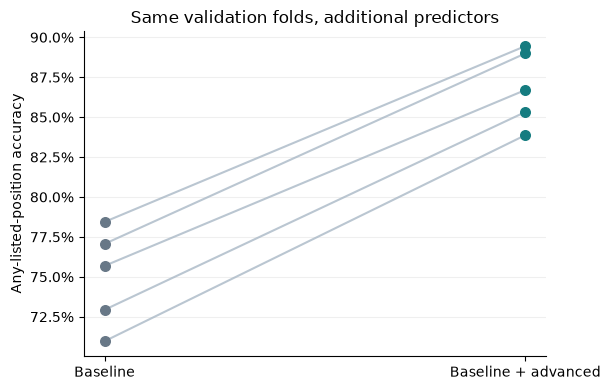

In [3]:
adv_folds = adv_pd.read_csv(adv_output / adv_model_kind / 'fold_scores.csv')
adv_paired = adv_folds.pivot(index='fold', columns='arm', values='any_position_accuracy')
adv_fig, adv_ax = adv_plt.subplots(figsize=(6.2, 4.0))
for adv_fold, adv_row in adv_paired.iterrows():
    adv_ax.plot([0, 1], adv_row[['Baseline', 'Baseline + advanced']], color='#a9b8c6', alpha=.8)
adv_ax.scatter(adv_np.zeros(len(adv_paired)), adv_paired['Baseline'], color='#687887', s=48, zorder=3)
adv_ax.scatter(adv_np.ones(len(adv_paired)), adv_paired['Baseline + advanced'], color='#157c80', s=48, zorder=3)
adv_ax.set_xticks([0, 1], ['Baseline', 'Baseline + advanced'])
adv_ax.set_ylabel('Any-listed-position accuracy')
adv_ax.set_title('Same validation folds, additional predictors')
adv_ax.yaxis.set_major_formatter(adv_plt.matplotlib.ticker.PercentFormatter(1))
adv_ax.grid(axis='y', alpha=.2)
adv_ax.spines[['top', 'right']].set_visible(False)
adv_fig.tight_layout()
adv_fig.savefig(adv_output / adv_model_kind / 'paired_accuracy.png', dpi=160)
adv_plt.show()

### Appendix: cohort changes, model checks and reproduction

The old eligibility rule (`90s >= 3`, no goalkeeper label) identifies the original labelled population. Current source minutes must additionally be at least 270. Ambiguous or unmatched identities, nationality/age conflicts, and inconsistent current exposure are excluded from **both** model arms. This is a matched subset, so these results do not establish accuracy for every player in the original CSV.

MF is the largest first-listed class; no class weighting was introduced, so the comparison changes the predictor set rather than the loss weighting. Any-listed scoring gives dual-position players more valid answers; the stricter columns above help assess the improvement. Position labels come from the earlier official CSV and can lag role changes. IDs, names, clubs, leagues, position columns and WhoScored ratings never enter the predictors.

The implementation and fitted configurations are in `advanced_position_comparison.py`. Exact source hashes and sample exclusions are in [the cohort manifest](advanced_position_results/cohort_manifest.json) and [matching audit](advanced_position_results/cohort_match_audit.csv). Each model folder contains fold scores, out-of-fold predictions and its result/configuration JSON. The fixed folds and holdout overlap as evaluation summaries; they are not independent replications. Results use one specified neural-network seed and do not establish future-season performance.

In [4]:
adv_audit = adv_pd.Series(adv_cohort['match_status_counts'], name='Records').rename_axis('Matching outcome').to_frame()
adv_classes = adv_pd.Series(adv_cohort['primary_class_counts'], name='Records').rename_axis('First-listed class').to_frame()
adv_classes['Share'] = adv_classes['Records'] / len(adv_data)
adv_display(adv_audit)
adv_display(adv_classes.assign(Share=adv_classes.Share.map(lambda value: f'{value:.1%}')))
adv_paired['Change (percentage points)'] = 100 * (adv_paired['Baseline + advanced'] - adv_paired['Baseline'])
adv_display(adv_paired.assign(**{
    'Baseline': adv_paired['Baseline'].map(lambda value: f'{value:.1%}'),
    'Baseline + advanced': adv_paired['Baseline + advanced'].map(lambda value: f'{value:.1%}'),
    'Change (percentage points)': adv_paired['Change (percentage points)'].map(lambda value: f'{value:+.1f}')
}))
adv_warning_count = sum(arm['convergence_warnings'] for arm in adv_result['arms'].values())
if adv_warning_count:
    print(f'Convergence warnings across paired fits: {adv_warning_count}; interpret the neural results with this limitation.')
if adv_model_kind == 'linear':
    print('Cross-validated position-mix MAE:', {name: round(arm['cv']['mix_mae'], 3) for name, arm in adv_result['arms'].items()})
print('Evaluated library versions:', adv_result['versions'])

,Records
Matching outcome,
included,1089
unmatched_identity,89
nationality_conflict,66
current_source_exposure_mismatch,22
fewer_than_270_current_minutes,2


,Records,Share
First-listed class,,
DF,391,35.9%
MF,536,49.2%
FW,162,14.9%


arm,Baseline,Baseline + advanced,Change (percentage points)
fold,,,
1,77.1%,89.0%,+11.9
2,72.9%,85.3%,+12.4
3,75.7%,86.7%,+11.0
4,78.4%,89.4%,+11.0
5,71.0%,83.9%,+12.9


Evaluated library versions: {'scikit-learn': '1.9.1', 'numpy': '2.5.4', 'pandas': '3.1.1'}
